In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

# 필요한 라이브러리

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [ ]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 필요한 함수

In [ ]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data

In [ ]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import warnings

def stepwise_feature_selection(X_train, y_train, variables=None, sl_enter=0.05, sl_remove=0.05):
    """
    전진 선택 + 후진 제거를 통한 변수 선택

    Parameters:
    - X_train: pd.DataFrame
    - y_train: pd.Series 또는 np.array
    - variables: 선택에 사용할 변수 리스트 (기본: X_train.columns)
    - sl_enter: 포함 기준 p-value
    - sl_remove: 제거 기준 p-value

    Returns:
    - selected_variables: 최종 선택된 변수 리스트
    """
    warnings.filterwarnings("ignore")

    if variables is None:
        variables = X_train.columns.tolist()

    y = y_train.copy()
    selected_variables = []
    steps = []
    sv_per_step = []
    adjusted_r_squared = []
    step = 0

    while len(variables) > 0:
        remainder = list(set(variables) - set(selected_variables))
        pval = pd.Series(index=remainder, dtype=float)

        # 전진 선택
        for col in remainder:
            X = sm.add_constant(X_train[selected_variables + [col]])
            model = sm.OLS(y, X).fit()
            pval[col] = model.pvalues[col]

        min_pval = pval.min()

        if min_pval < sl_enter:
            best_var = pval.idxmin()
            selected_variables.append(best_var)

            # 후진 제거
            while len(selected_variables) > 0:
                X_selected = sm.add_constant(X_train[selected_variables])
                model = sm.OLS(y, X_selected).fit()
                selected_pvals = model.pvalues.drop('const')

                max_pval = selected_pvals.max()
                if max_pval >= sl_remove:
                    worst_var = selected_pvals.idxmax()
                    selected_variables.remove(worst_var)
                else:
                    break

            # 결과 저장
            step += 1
            steps.append(step)
            sv_per_step.append(selected_variables.copy())
            adj_r2 = sm.OLS(y, sm.add_constant(X_train[selected_variables])).fit().rsquared_adj
            adjusted_r_squared.append(adj_r2)

        else:
            break

    # 그래프 출력
    plt.figure(figsize=(12, 6))
    plt.xticks(steps, [f'Step {s}\n' + '\n'.join(sv) for s, sv in zip(steps, sv_per_step)], fontsize=10)
    plt.plot(steps, adjusted_r_squared, marker='o', color='blue')
    plt.ylabel('Adjusted R Squared', fontsize=12)
    plt.xlabel('Step', fontsize=12)
    plt.title('단계별 선택법 과정', fontsize=14)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return selected_variables

# 데이터 불러오기

In [ ]:
# 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_21_v2.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_22_v2.csv')

In [ ]:
df_21.head(3)

,time,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),...,중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM_lag1,PM10_1
0,2021-01-01 01:00:00,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,...,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,11.0,25.0
1,2021-01-01 02:00:00,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,...,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0,27.0
2,2021-01-01 03:00:00,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,...,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,17.0,23.0


In [ ]:
df_21 = df_21.drop(['time', 'PM_lag1'], axis=1)
df_22 = df_22.drop(['time', 'PM_lag1'], axis=1)

In [ ]:
df_21['PM10_1'] = df_21['PM10'].shift(-1)

In [ ]:
df_22['PM10_1'] = df_22['PM10'].shift(-1)

In [ ]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [ ]:
df_21

,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),...,전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM10_1
0,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,270.0,...,0.0,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,25.0
1,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,270.0,...,0.0,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0
2,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,250.0,...,0.0,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,23.0
3,0.003,0.6,0.011,0.027,23.0,13.0,-9.3,0.0,0.3,0.0,...,0.0,0,0.0,2000,-7.5,-1.3,-1.0,0.2,1.5,24.0
4,0.003,0.6,0.008,0.032,24.0,14.0,-9.7,0.0,1.9,20.0,...,0.0,0,0.0,2000,-7.6,-1.3,-1.0,0.2,1.5,26.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8753,0.003,0.4,0.029,0.018,24.0,9.0,-5.9,0.0,2.2,230.0,...,0.0,0,0.0,2000,-3.4,-0.3,-0.6,-0.1,1.0,25.0
8754,0.003,0.4,0.026,0.019,25.0,10.0,-6.4,0.0,2.2,250.0,...,0.0,0,0.0,2000,-4.5,-0.5,-0.7,-0.1,1.0,26.0
8755,0.003,0.4,0.025,0.020,26.0,8.0,-6.3,0.0,4.1,320.0,...,0.0,0,0.0,2000,-5.3,-0.6,-0.8,-0.1,1.0,27.0
8756,0.003,0.4,0.030,0.014,27.0,9.0,-6.7,0.0,4.8,320.0,...,0.0,0,0.0,2000,-5.7,-0.7,-0.8,-0.1,1.0,20.0


# [1] 전체 데이터 사용해서 모델링

In [ ]:
# PM10을 제외하고 모델링하려면 다음의 코드를 실행
# df_21 = df_21.drop('PM10', axis=1)
# df_22 = df_22.drop('PM10', axis=1)

In [ ]:
X_train = df_21.loc[:, :'30cm 지중온도(°C)'].values
X_test = df_22.loc[:, :'30cm 지중온도(°C)'].values

y_train = df_21['PM10_1'].values
y_test = df_22['PM10_1'].values

In [ ]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

## [1-1] 랜덤포레스트

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

In [ ]:
rf_model = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
-17.10433562165819


In [ ]:
rf_model = grid_search.best_estimator_

In [ ]:
y_pred = rf_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

5.984006213801716


In [ ]:
r2_score(y_test, y_pred)

0.9351758138165314

## [1-2] XGBRegressor

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],  # L1
    'reg_lambda': [1, 10]   # L2
}

In [ ]:
xgb_model = XGBRegressor(random_state=42, objective='reg:squarederror')

grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1], 'max_depth': [3, 6, 10],
                         'n_estimators': [100, 300], 'reg_alpha': [0, 0.1],
                         'reg_lambda': [1, 10], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 1, 'subsample': 1.0}
-17.31467360589408


In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
y_pred = xgb_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.762859731181054


In [ ]:
r2_score(y_test, y_pred)

0.9398785980166301

##[1-3] LightGBM

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [10, 20, -1],     # -1은 제한 없음
    'learning_rate': [0.01, 0.1],
    'num_leaves': [31, 50],        # 기본값 31
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [ ]:
lgbm_model = LGBMRegressor(random_state=42)

grid_search = GridSearchCV(estimator=lgbm_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002753 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3955
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 28
[LightGBM] [Info] Start training from score 38.787965


GridSearchCV(cv=5, estimator=LGBMRegressor(random_state=42), n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1],
                         'max_depth': [10, 20, -1], 'n_estimators': [100, 300],
                         'num_leaves': [31, 50], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 10, 'n_estimators': 300, 'num_leaves': 31, 'subsample': 0.8}
-17.908265988649465


In [ ]:
lgbm_model = grid_search.best_estimator_

In [ ]:
y_pred = lgbm_model.predict(X_test)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

6.0640482184289635


In [ ]:
r2_score(y_test, y_pred)

0.9334300403864328

# [2] 일부 데이터만 사용해서 모델링

##[2-1] 결측치가 많았던 피처 제외

In [ ]:
# 일조(hr), 일사(MJ/m2), 적설(cm), 3시간신적설(cm), 최저운고(100m ) 제외(강수량은 제외 안함)
# 제외할 컬럼 리스트
columns_to_drop = ['일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '최저운고(100m )']

# 해당 컬럼들을 제거한 새로운 데이터프레임 생성
temp_21 = df_21.drop(columns=columns_to_drop)
temp_22 = df_22.drop(columns=columns_to_drop)

In [ ]:
temp_21.columns

Index(['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)',
       '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)',
       '해면기압(hPa)', '전운량(10분위)', '중하층운량(10분위)', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_1'],
      dtype='object')

In [ ]:
X_train = temp_21.loc[:, :'30cm 지중온도(°C)'].values
X_test = temp_22.loc[:, :'30cm 지중온도(°C)'].values

y_train = temp_21['PM10_1'].values
y_test = temp_22['PM10_1'].values

In [ ]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

#### [2-1-1] 랜덤포레스트

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

In [ ]:
rf_model = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
-17.094106321902625


In [ ]:
rf_model = grid_search.best_estimator_
y_pred = rf_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.963307124758469


In [ ]:
r2_score(y_test, y_pred)

0.935623500821557

#### [2-1-2] XGBRegressor

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],  # L1
    'reg_lambda': [1, 10]   # L2
}

In [ ]:
xgb_model = XGBRegressor(random_state=42, objective='reg:squarederror')

grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1], 'max_depth': [3, 6, 10],
                         'n_estimators': [100, 300], 'reg_alpha': [0, 0.1],
                         'reg_lambda': [1, 10], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1, 'subsample': 1.0}
-17.29120205339079


In [ ]:
xgb_model = grid_search.best_estimator_
y_pred = xgb_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.735404392567926


In [ ]:
r2_score(y_test, y_pred)

0.9404500925577824

#### [2-1-3] LightGBM

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [10, 20, -1],     # -1은 제한 없음
    'learning_rate': [0.01, 0.1],
    'num_leaves': [31, 50],        # 기본값 31
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [ ]:
lgbm_model = LGBMRegressor(random_state=42)

grid_search = GridSearchCV(estimator=lgbm_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000636 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3575
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 23
[LightGBM] [Info] Start training from score 38.787965


GridSearchCV(cv=5, estimator=LGBMRegressor(random_state=42), n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1],
                         'max_depth': [10, 20, -1], 'n_estimators': [100, 300],
                         'num_leaves': [31, 50], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 20, 'n_estimators': 300, 'num_leaves': 31, 'subsample': 0.8}
-17.934618306512967


In [ ]:
lgbm_model = grid_search.best_estimator_
y_pred = lgbm_model.predict(X_test)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

6.105317561173864


In [ ]:
r2_score(y_test, y_pred)

0.9325208632640876

##[2-2] 단계별 선택법

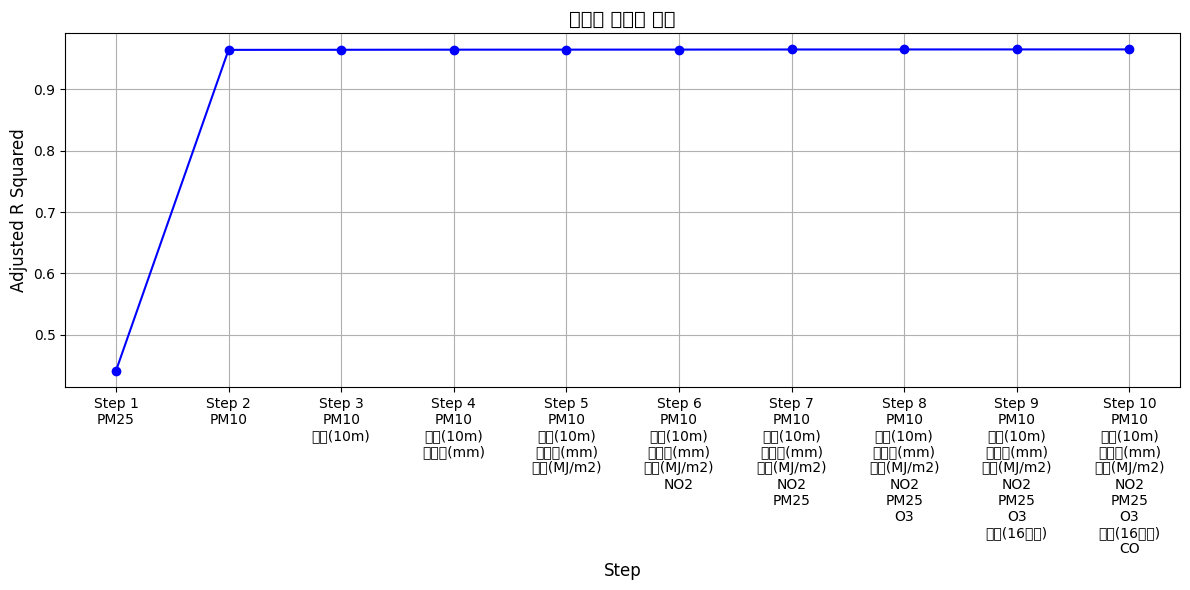

In [ ]:
selected_variables = stepwise_feature_selection(df_21.iloc[:, :-1], df_21['PM10_1'])

In [ ]:
vif(df_21, selected_variables)

,변수,VIF
1,PM10,1.954198
2,시정(10m),1.661030
3,강수량(mm),1.132786
4,일사(MJ/m2),1.282947
5,NO2,5.045086
6,PM25,3.835978
7,O3,2.080808
8,풍향(16방위),1.109164
9,CO,5.160519


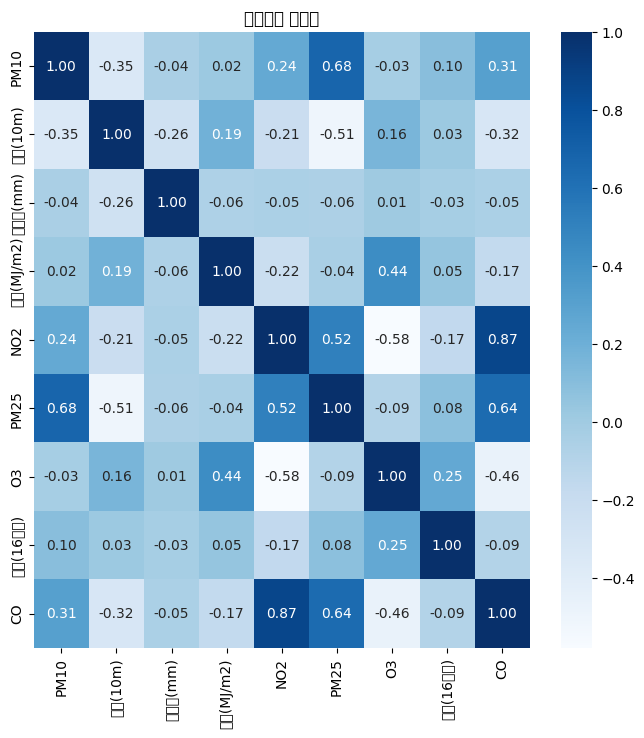

In [ ]:
df_21_corr = df_21[selected_variables].corr()
plt.figure(figsize=(8, 8))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [ ]:
X_train = df_21[selected_variables].values
X_test = df_22[selected_variables].values

y_train = df_21['PM10_1'].values
y_test = df_22['PM10_1'].values

In [ ]:
# 스케일링
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

#### [2-2-1] 랜덤포레스트

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

In [ ]:
rf_model = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
-17.38230357184782


In [ ]:
rf_model = grid_search.best_estimator_
y_pred = rf_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.8029796005868866


In [ ]:
r2_score(y_test, y_pred)

0.939038577937434

#### [2-2-2] XGMRegressor

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],  # L1
    'reg_lambda': [1, 10]   # L2
}


In [ ]:
xgb_model = XGBRegressor(random_state=42, objective='reg:squarederror')

grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1], 'max_depth': [3, 6, 10],
                         'n_estimators': [100, 300], 'reg_alpha': [0, 0.1],
                         'reg_lambda': [1, 10], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 10, 'subsample': 1.0}
-17.249685889983347


In [ ]:
xgb_model = grid_search.best_estimator_
y_pred = xgb_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.84074851373599


In [ ]:
r2_score(y_test, y_pred)

0.9382424560844985

#### [2-2-3] LightGBM

In [ ]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [10, 20, -1],     # -1은 제한 없음
    'learning_rate': [0.01, 0.1],
    'num_leaves': [31, 50],        # 기본값 31
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [ ]:
lgbm_model = LGBMRegressor(random_state=42)

grid_search = GridSearchCV(estimator=lgbm_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002122 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1106
[LightGBM] [Info] Number of data points in the train set: 8758, number of used features: 9
[LightGBM] [Info] Start training from score 38.787965


GridSearchCV(cv=5, estimator=LGBMRegressor(random_state=42), n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1],
                         'max_depth': [10, 20, -1], 'n_estimators': [100, 300],
                         'num_leaves': [31, 50], 'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 20, 'n_estimators': 300, 'num_leaves': 50, 'subsample': 0.8}
-17.985319484519454


In [ ]:
lgbm_model = grid_search.best_estimator_
y_pred = lgbm_model.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred)))

5.831810968144472


In [ ]:
r2_score(y_test, y_pred)

0.9384313149460942